# 04 Maps and figures

## 0. Setup

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import rasterio
from rasterio.windows import Window

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT   = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA   = ROOT / "data"; FIGDIR = ROOT / "figures"; TABDIR = ROOT / "tables"
FIGDIR.mkdir(exist_ok=True); TABDIR.mkdir(exist_ok=True)

RASTER_CLASS = DATA / "rasters" / "classmap_fullcoast_30m.tif"
GULF = dict(lon=(135.0, 141.5), lat=(-18.0, -14.0))
PIXEL_HA = 2522.33 / 29453

# Okabe-Ito, CVD-checked. Class 2 is the vermillion so the rare class reads.
C_NONE, C_DIEBACK, C_OTHER = "#009E73", "#D55E00", "#0072B2"
C_INK, C_MUTED, C_GRID, C_SEA = "#1a1a1a", "#6b6b6b", "#e0e0e0", "#f4f7fa"
W1, W2 = 3.46, 7.09          # CEE single (88 mm) / double (180 mm) column

plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 9,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.edgecolor": C_MUTED, "axes.linewidth": 0.6,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "text.color": C_INK, "axes.labelcolor": C_INK,
    "figure.dpi": 130, "savefig.dpi": 400, "savefig.bbox": "tight",
})

def tidy(ax):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(True, color=C_GRID, lw=0.5); ax.set_axisbelow(True); return ax

def scalebar(ax, km=100, lat=-16.0):
    '''A scale bar in degrees of longitude at this latitude.'''
    deg = km / (111.320 * np.cos(np.radians(lat)))
    x0 = ax.get_xlim()[0] + 0.06*(ax.get_xlim()[1]-ax.get_xlim()[0])
    y0 = ax.get_ylim()[0] + 0.08*(ax.get_ylim()[1]-ax.get_ylim()[0])
    ax.plot([x0, x0+deg], [y0, y0], color=C_INK, lw=1.6, solid_capstyle="butt")
    ax.annotate(f"{km} km", xy=(x0+deg/2, y0), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=6.5, color=C_INK)

def northarrow(ax):
    x = ax.get_xlim()[1] - 0.05*(ax.get_xlim()[1]-ax.get_xlim()[0])
    y0 = ax.get_ylim()[0] + 0.08*(ax.get_ylim()[1]-ax.get_ylim()[0])
    dy = 0.10*(ax.get_ylim()[1]-ax.get_ylim()[0])
    ax.annotate("N", xy=(x, y0+dy), xytext=(x, y0), ha="center", fontsize=7,
                color=C_INK,
                arrowprops=dict(arrowstyle="-|>", color=C_INK, lw=0.9))

print("raster:", RASTER_CLASS, "exists:", RASTER_CLASS.exists())

raster: C:\mangrove-resilience\data\rasters\classmap_fullcoast_30m.tif exists: True


## 1. Read the class map at display resolution

In [2]:
BLOCK = 24          # source pixels per display cell; 24 -> ~720 m

with rasterio.open(RASTER_CLASS) as src:
    H, W = src.height, src.width
    bounds = src.bounds
    oh, ow = H // BLOCK, W // BLOCK
    present = np.zeros((3, oh, ow), dtype=bool)   # classes 1, 2, 3

    for i in range(oh):
        win = Window(0, i*BLOCK, ow*BLOCK, BLOCK)
        row = src.read(1, window=win)
        for k, cls in enumerate((1, 2, 3)):
            m = (row == cls).reshape(BLOCK, ow, BLOCK)
            present[k, i, :] = m.any(axis=(0, 2))

    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

print(f"source {H:,} x {W:,}   display {oh} x {ow}")
for k, cls in enumerate((1, 2, 3)):
    print(f"  class {cls}: {present[k].sum():,} display cells")

source 14,944 x 24,120   display 622 x 1005
  class 1: 8,540 display cells
  class 2: 986 display cells
  class 3: 3,987 display cells


## 2. Figure 6 - study area

Mangrove extent coloured by disturbance class, with a locator inset placing
the Gulf in northern Australia.

zoom windows (lon, lat, dieback pixels):
  135.10, -15.05   2,145
  139.30, -17.50   4,257
  140.00, -17.85   3,227


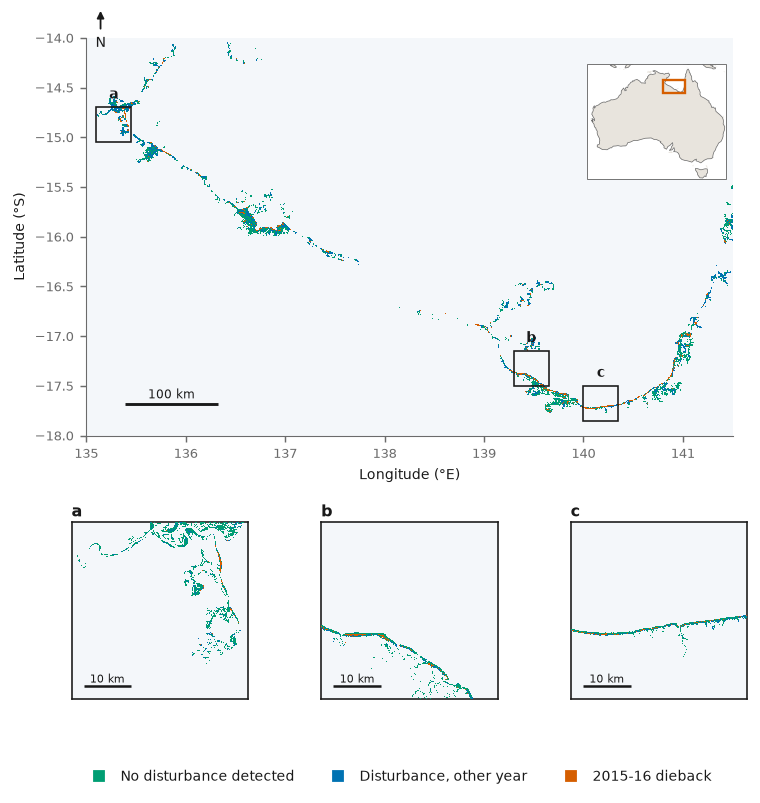

In [3]:
# Figure 6 - study area with data-driven zoom panels

from rasterio.windows import from_bounds

ZOOM_DEG   = 0.35        
SPLIT_LON  = 138.5       # the natural gap in mangrove distribution

pxz = pd.read_csv(DATA / "phase3_pixels.csv").replace(-9999, np.nan)
gx = (np.floor(pxz.longitude / ZOOM_DEG) * ZOOM_DEG)
gy = (np.floor(pxz.latitude  / ZOOM_DEG) * ZOOM_DEG)
dens = (pd.DataFrame({"x": gx, "y": gy})
          .value_counts().rename("n").reset_index())

def pick(df, n=1):
    out = []
    for _, r in df.iterrows():
        if len(out) >= n:
            break
        if all(abs(r.x - o.x) > ZOOM_DEG or abs(r.y - o.y) > ZOOM_DEG
               for o in out):
            out.append(r)
    return out

west = pick(dens[dens.x < SPLIT_LON], 1)
east = pick(dens[dens.x >= SPLIT_LON], 2)
zooms = west + east
print("zoom windows (lon, lat, dieback pixels):")
for z in zooms:
    print(f"  {z.x:.2f}, {z.y:.2f}   {int(z.n):,}")

# layout 
fig = plt.figure(figsize=(W2, 6.6))
gs  = fig.add_gridspec(2, 3, height_ratios=[2.25, 1.0],
                       hspace=0.30, wspace=0.16)
ax  = fig.add_subplot(gs[0, :])
axz = [fig.add_subplot(gs[1, i]) for i in range(3)]

ax.set_facecolor(C_SEA)
handles = []
for k, (cls, col, lab) in enumerate([
        (1, C_NONE,    "No disturbance detected"),
        (3, C_OTHER,   "Disturbance, other year"),
        (2, C_DIEBACK, "2015-16 dieback")]):
    idx = {1: 0, 2: 1, 3: 2}[cls]
    layer = np.ma.masked_where(~present[idx], present[idx].astype(float))
    ax.imshow(layer, extent=extent, origin="upper",
              cmap=ListedColormap([col]), vmin=0, vmax=1,
              interpolation="nearest", zorder=3 + k)
    handles.append(plt.Line2D([], [], marker="s", linestyle="none",
                              color=col, markersize=6, label=lab))

ax.set_xlim(*GULF["lon"]); ax.set_ylim(*GULF["lat"])
ax.set_aspect("equal")
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°S)")
for s in ("top", "right"): ax.spines[s].set_visible(False)
scalebar(ax)

ax.annotate("N", xy=(0.022, 1.077), xytext=(0.022, 1.005),
            xycoords="axes fraction", textcoords="axes fraction",
            ha="center", va="top", fontsize=8, color=C_INK,
            annotation_clip=False,
            arrowprops=dict(arrowstyle="-|>", color=C_INK, lw=1.0))

# zoom boxes 
for lab, z in zip("abc", zooms):
    ax.add_patch(Rectangle((z.x, z.y), ZOOM_DEG, ZOOM_DEG, fill=False,
                           edgecolor=C_INK, lw=0.9, zorder=9))
    ax.annotate(lab, xy=(z.x + ZOOM_DEG/2, z.y + ZOOM_DEG),
                xytext=(0, 5), textcoords="offset points", ha="center",
                fontsize=8, fontweight="bold", color=C_INK, zorder=9)

try:
    import cartopy.crs as ccrs, cartopy.feature as cfeature
    axl = ax.inset_axes([0.775, 0.60, 0.215, 0.38],
                        projection=ccrs.PlateCarree())
    axl.set_extent([112, 154, -44, -9], crs=ccrs.PlateCarree())
    axl.add_feature(cfeature.LAND, facecolor="#e8e4dd", zorder=1)
    axl.add_feature(cfeature.OCEAN, facecolor="white", zorder=0)
    axl.coastlines(resolution="110m", linewidth=0.4, color=C_MUTED, zorder=2)
    axl.add_patch(Rectangle((GULF["lon"][0], GULF["lat"][0]),
                            GULF["lon"][1]-GULF["lon"][0],
                            GULF["lat"][1]-GULF["lat"][0],
                            fill=False, edgecolor=C_DIEBACK, lw=1.3,
                            zorder=5, transform=ccrs.PlateCarree()))
except ImportError:
    axl = ax.inset_axes([0.775, 0.60, 0.215, 0.38])
    axl.set_xlim(112, 154); axl.set_ylim(-44, -9); axl.set_aspect("equal")
    axl.add_patch(Rectangle((GULF["lon"][0], GULF["lat"][0]),
                            GULF["lon"][1]-GULF["lon"][0],
                            GULF["lat"][1]-GULF["lat"][0],
                            fill=False, edgecolor=C_DIEBACK, lw=1.3))
    axl.set_xticks([]); axl.set_yticks([])
for s in axl.spines.values():
    s.set_edgecolor(C_MUTED); s.set_linewidth(0.5)

# zoom panels, read at native 30 m
with rasterio.open(RASTER_CLASS) as src:
    for a, lab, z in zip(axz, "abc", zooms):
        w = from_bounds(z.x, z.y, z.x + ZOOM_DEG, z.y + ZOOM_DEG,
                        src.transform)
        sub = src.read(1, window=w)
        ext = [z.x, z.x + ZOOM_DEG, z.y, z.y + ZOOM_DEG]
        a.set_facecolor(C_SEA)
        for k, (cls, col) in enumerate([(1, C_NONE), (3, C_OTHER),
                                        (2, C_DIEBACK)]):
            m = np.ma.masked_where(sub != cls, np.ones_like(sub, float))
            a.imshow(m, extent=ext, origin="upper",
                     cmap=ListedColormap([col]), vmin=0, vmax=1,
                     interpolation="nearest", zorder=3 + k)
        a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3])
        a.set_aspect("equal")
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_edgecolor(C_INK); s.set_linewidth(0.9)
        a.set_title(lab, loc="left", fontweight="bold", fontsize=9, pad=3)
        # a 10 km bar inside each panel
        km = 10 / (111.320 * np.cos(np.radians(z.y + ZOOM_DEG/2)))
        x0 = ext[0] + 0.07*ZOOM_DEG; y0 = ext[2] + 0.07*ZOOM_DEG
        a.plot([x0, x0+km], [y0, y0], color=C_INK, lw=1.4,
               solid_capstyle="butt", zorder=9)
        a.annotate("10 km", xy=(x0+km/2, y0), xytext=(0, 2),
                   textcoords="offset points", ha="center",
                   fontsize=6, color=C_INK, zorder=9)

fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.005), fontsize=8,
           handletextpad=0.5, columnspacing=2.0)

fig.savefig(FIGDIR / "fig6_study_area.png", bbox_inches="tight")
plt.show()

## 3. Figure 7 - recovery across the dieback

Drawn from the per-pixel census, aggregated to ~5 km cells so that individual
pixels do not dominate and the spatial pattern is legible.

**Left panel** — median ENSO-adjusted recovery ratio. A diverging ramp centred
on the 0.80 recovery threshold, so brown is below it and teal above. 

**Right panel** — the fraction of each cell's dieback area still below
threshold. Sequential, because this is a magnitude from zero.

148 cells, 2,450 ha of dieback


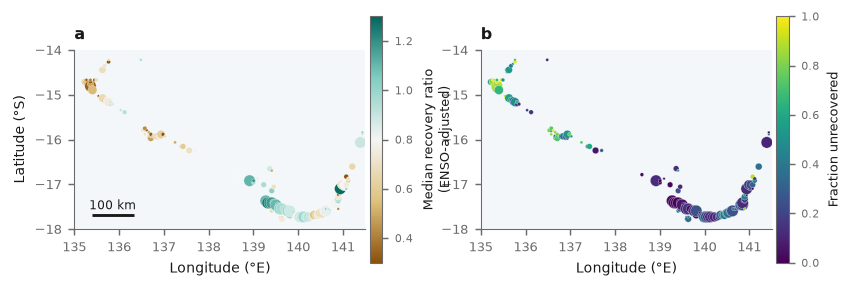

In [4]:
px = pd.read_csv(DATA / "phase3_pixels.csv").replace(-9999, np.nan)
CELL = 0.045                      # ~5 km
px["cx"] = np.floor(px.longitude / CELL) * CELL
px["cy"] = np.floor(px.latitude  / CELL) * CELL

g = (px.groupby(["cx", "cy"])
       .agg(n=("magnitude", "size"),
            rr=("recovery_ratio_adj", "median"),
            unrec=("unrecovered", "mean"))
       .reset_index())
g = g[g.n >= 20]
print(f"{len(g)} cells, {g.n.sum()*PIXEL_HA:,.0f} ha of dieback")

DIV = LinearSegmentedColormap.from_list(
    "recovery", ["#8c510a", "#dfc27d", "#f5f5f5", "#80cdc1", "#01665e"])

fig, axes = plt.subplots(1, 2, figsize=(W2, 2.9))
fig.subplots_adjust(wspace=0.32)

for ax, (col, cmap, lab, vmin, vmax, centre) in zip(axes, [
        ("rr",    DIV,      "Median recovery ratio\n(ENSO-adjusted)", 0.3, 1.3, 0.8),
        ("unrec", "viridis", "Fraction unrecovered",                   0.0, 1.0, None)]):
    ax.set_facecolor(C_SEA)
    if centre is not None:
        # stretch so the threshold sits at the neutral midpoint
        half = max(centre - vmin, vmax - centre)
        vmin, vmax = centre - half, centre + half
    s = ax.scatter(g.cx, g.cy, c=g[col], s=np.clip(g.n/12, 2, 40),
                   cmap=cmap, vmin=vmin, vmax=vmax,
                   edgecolor="white", linewidth=0.15, zorder=3)
    cb = fig.colorbar(s, ax=ax, pad=0.015, fraction=0.040)
    cb.set_label(lab, fontsize=7); cb.ax.tick_params(labelsize=6)
    ax.set_xlim(*GULF["lon"]); ax.set_ylim(*GULF["lat"])
    ax.set_aspect("equal"); ax.set_xlabel("Longitude (°E)")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

axes[0].set_ylabel("Latitude (°S)")
axes[0].set_title("a", loc="left", fontweight="bold", fontsize=9)
axes[1].set_title("b", loc="left", fontweight="bold", fontsize=9)
scalebar(axes[0])
fig.savefig(FIGDIR / "fig7_recovery_map.png")
plt.show()

## 4. Figure 8 - patch structure

A patch is a contiguous group of dieback pixels, found with `scipy.ndimage.label` using
8-connectivity so diagonal neighbours count appropriate for a narrow coastal
fringe, where 4-connectivity would break a diagonal strip into fragments.

**Why patch size matters ecologically.** Recovery in mangrove depends on
propagule supply from surviving stands. A 1 ha gap inside intact forest is
seeded from every side; a 50 ha block has an interior far from any seed source.
So if the unrecovered fraction rises with patch size, that is evidence for a
propagule-limitation mechanism.

patches (>= 5 px): 952
total area        : 2,522.3 ha
median patch      : 0.77 ha
largest patch     : 144.9 ha
area in patches > 10 ha: 54.3%


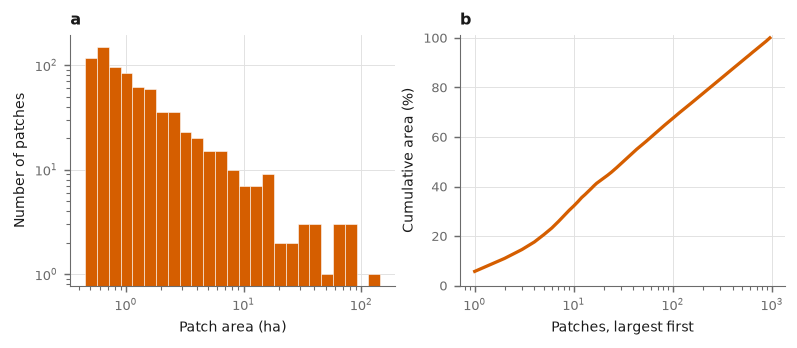

In [5]:
from scipy import ndimage

with rasterio.open(RASTER_CLASS) as src:
    cls = src.read(1)
    tr = src.transform

lab_arr, n_patch = ndimage.label(cls == 2, structure=np.ones((3, 3), int))
sizes = ndimage.sum(np.ones_like(lab_arr), lab_arr,
                    index=np.arange(1, n_patch+1)).astype(int)
areas = sizes * PIXEL_HA

patch = pd.DataFrame({"patch_id": np.arange(1, n_patch+1),
                      "pixels": sizes, "area_ha": areas})
cy, cx = zip(*ndimage.center_of_mass(cls == 2, lab_arr,
                                     np.arange(1, n_patch+1)))
patch["lon"], patch["lat"] = rasterio.transform.xy(tr, np.array(cy), np.array(cx))
patch = patch[patch.pixels >= 5]        # the 5-pixel minimum mapping unit
patch.to_csv(TABDIR / "patch_stats.csv", index=False)

print(f"patches (>= 5 px): {len(patch):,}")
print(f"total area        : {patch.area_ha.sum():,.1f} ha")
print(f"median patch      : {patch.area_ha.median():.2f} ha")
print(f"largest patch     : {patch.area_ha.max():,.1f} ha")
print(f"area in patches > 10 ha: {patch.loc[patch.area_ha>10,'area_ha'].sum()/patch.area_ha.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(W2, 2.5))

ax = tidy(axes[0])
bins = np.logspace(np.log10(0.45), np.log10(max(patch.area_ha.max(), 1)), 26)
ax.hist(patch.area_ha, bins=bins, color=C_DIEBACK, edgecolor="white", lw=0.3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Patch area (ha)"); ax.set_ylabel("Number of patches")
ax.set_title("a", loc="left", fontweight="bold", fontsize=9)

ax = tidy(axes[1])
o = patch.sort_values("area_ha", ascending=False)
ax.plot(np.arange(1, len(o)+1), np.cumsum(o.area_ha)/o.area_ha.sum()*100,
        color=C_DIEBACK, lw=1.8)
ax.set_xscale("log")
ax.set_xlabel("Patches, largest first"); ax.set_ylabel("Cumulative area (%)")
ax.set_ylim(0, 101)
ax.set_title("b", loc="left", fontweight="bold", fontsize=9)

fig.savefig(FIGDIR / "fig8_patches.png")
plt.show()

## 5. Does recovery depend on patch size?

Joins each dieback pixel to its patch, then asks whether the unrecovered
fraction rises with patch area. Spearman and spatial block bootstrap methods were used becausepatches are not independent of their
neighbours.

In [6]:
with rasterio.open(RASTER_CLASS) as src:
    rows, cols = rasterio.transform.rowcol(src.transform,
                                           px.longitude.values, px.latitude.values)
rows = np.clip(np.asarray(rows), 0, lab_arr.shape[0]-1)
cols = np.clip(np.asarray(cols), 0, lab_arr.shape[1]-1)
px["patch_id"] = lab_arr[rows, cols]

pj = (px[px.patch_id > 0]
        .groupby("patch_id")
        .agg(n=("magnitude", "size"),
             unrec=("unrecovered", "mean"),
             rr=("recovery_ratio_adj", "median"),
             lon=("longitude", "mean"), lat=("latitude", "mean"))
        .reset_index())
pj["area_ha"] = pj.n * PIXEL_HA
pj = pj[pj.n >= 5]

from scipy import stats
RNG = np.random.default_rng(2026)
def bb_spearman(x, y, lon, lat, block=0.25, n_boot=2000):
    ok = np.isfinite(x) & np.isfinite(y)
    x, y, lon, lat = (np.asarray(a)[ok] for a in (x, y, lon, lat))
    bid = (np.floor(lon/block).astype(int).astype(str) + "_" +
           np.floor(lat/block).astype(int).astype(str))
    bl, inv = np.unique(bid, return_inverse=True)
    idx = [np.flatnonzero(inv == k) for k in range(len(bl))]
    if len(bl) < 3: return dict(rho=np.nan, ci=(np.nan, np.nan), n=int(ok.sum()))
    pt = stats.spearmanr(x, y).statistic
    b = np.empty(n_boot)
    for i in range(n_boot):
        sel = np.concatenate([idx[p] for p in RNG.integers(0, len(bl), len(bl))])
        b[i] = stats.spearmanr(x[sel], y[sel]).statistic
    return dict(rho=float(pt), ci=tuple(np.nanpercentile(b, [2.5, 97.5])),
                n=int(ok.sum()), n_blocks=len(bl))

res = bb_spearman(pj.area_ha, pj.unrec, pj.lon, pj.lat)
print(f"patch area vs unrecovered fraction:")
print(f"  Spearman rho = {res['rho']:+.3f}  95% CI "
      f"[{res['ci'][0]:+.3f}, {res['ci'][1]:+.3f}]   n = {res['n']:,} patches")
print("\nInterpretation: a positive interval clear of zero supports propagule")
print("limitation - bigger patches recover less. An interval spanning zero means")
print("patch size does not explain recovery")

with open(TABDIR / "patch_recovery.json", "w") as f:
    json.dump({"spearman_rho": res["rho"],
               "ci95": [float(res["ci"][0]), float(res["ci"][1])],
               "n_patches": res["n"]}, f, indent=2)

patch area vs unrecovered fraction:
  Spearman rho = -0.016  95% CI [-0.111, +0.078]   n = 952 patches

Interpretation: a positive interval clear of zero supports propagule
limitation - bigger patches recover less. An interval spanning zero means
patch size does not explain recovery
